# Gash (Templar)

Gash is a Templar melee nuke. The caster cuts themselves for **2.5% of current HP** to deliver
one heavy, weapon-scaled blow to an adjacent target. It is the Templar's main "spend HP for
damage" button. Its damage scales with both the caster's **weapon value (WV)** and their
**modified Gash skill**.

| | |
|---|---|
| Class | Templar |
| Target | Adjacent enemy (Chebyshev distance 1) |
| Cost | `max(1, a_hp/40)` milli-HP, i.e. 2.5% of **current** HP; refused if that would kill |
| Cooldown | 10 s |
| Damage type | 0 (melee, `(dam − armor) × ¼`) |
| Source | `server/src/driver/skill/templar.rs::skill_gash` |

---

# Formula

Let $W = \max(1, \text{WV})$ be the caster's weapon value and $p$ the modified Gash skill. Gash
uses $p$ directly, with no immunity or race modifier:

$$
\text{bonus}\% = \operatorname{clamp}(3p,\ 30,\ 600)
\qquad
\text{dam} = \left\lfloor \frac{W\,(100 + \text{bonus}\%)}{100} \right\rfloor + \text{rand}(3W)
$$

where $\text{rand}(n)$ is uniform over $0 \dots n-1$. The hit is passed to `do_hurt` as type 0, so
the target takes

$$
\text{HP lost} = \frac{\max(0,\ \text{dam} - \text{armor}) \times 250}{1000}
$$

| Modified skill | bonus % | Fixed part | Notes |
|---|---|---|---|
| 1 – 10 | 30 | $1.3W$ | floor clamp |
| 30 | 90 | $1.9W$ | |
| 100 | 300 | $4W$ | |
| 150 | 450 | $5.5W$ | |
| ≥ 200 | 600 | $7W$ | ceiling clamp |

The random part, $\text{rand}(3W)$, averages $1.5W$ at every skill level. Expected raw damage
before armor is therefore $W\,(1 + \text{bonus}\%/100) + 1.5W - 0.5$.

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE

# Model

In [2]:
def gash_bonus_pct(p):
    return mm.clamp(np.asarray(p) * 3, 30, 600)


def gash_fixed(p, wv):
    w = np.maximum(1, wv)
    return mm.idiv(w * (100 + gash_bonus_pct(p)), 100)


def gash_expected_hp(p, wv, armor=0):
    """Exact expected HP removed from the target by one Gash."""
    w = np.maximum(1, wv)
    return mm.expected_hurt_uniform(gash_fixed(p, wv), 3 * w, armor, kind=0)


def gash_self_cost_hp(current_hp):
    """HP the caster loses: `max(1, a_hp/40)` milli-HP."""
    a_hp = np.asarray(current_hp) * 1000
    return np.maximum(1, mm.idiv(a_hp, 40)) / 1000


def melee_expected_hp(wv, strength, armor=0):
    """Plain auto-attack on a normal hit (die >= 3): WV + rand(6)+1 + rand(str/2), no bonus."""
    # Sum of two independent uniforms; enumerate exactly for the armor clamp.
    a = np.arange(6) + 1
    b = np.arange(max(1, strength // 2)) if strength > 3 else np.array([0])
    dam = wv + a[:, None] + b[None, :]
    return mm.hurt_hp(dam, armor, 0).mean()

# Validation

The server has no numeric Gash unit test. Instead, the cells below check the in-code comment
("+90% at power=30, +450% at power=150"), the clamps, and the closed-form expectation against
brute-force enumeration of every die roll.

In [3]:
assert gash_bonus_pct(30) == 90
assert gash_bonus_pct(150) == 450
assert gash_bonus_pct(1) == 30 and gash_bonus_pct(10) == 30
assert gash_bonus_pct(200) == 600 and gash_bonus_pct(400) == 600
assert gash_fixed(100, 40) == 160          # 40 * 400 / 100

for p, wv, armor in [(1, 1, 0), (50, 25, 30), (120, 40, 80), (200, 60, 0), (5, 3, 40)]:
    w = max(1, wv)
    brute = np.mean([mm.hurt_hp(gash_fixed(p, wv) + k, armor, 0) for k in range(3 * w)])
    assert np.isclose(gash_expected_hp(p, wv, armor), brute), (p, wv, armor)

assert gash_self_cost_hp(400) == 10.0       # 2.5% of 400 HP
assert gash_self_cost_hp(0.02) == 0.001     # floor of 1 milli-HP
print("Gash model OK")

Gash model OK


# Plots

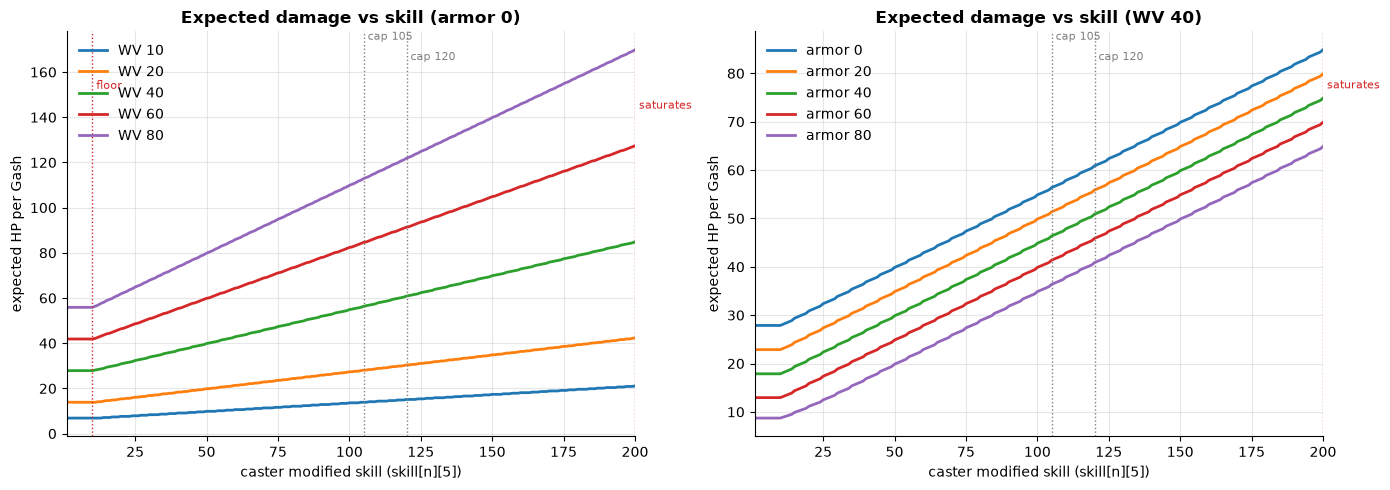

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for wv in mm.WV_SWEEP:
    ax.plot(P, gash_expected_hp(P, wv, armor=0), label=f"WV {wv}")
mm.skill_axis(ax, "expected HP per Gash", "Expected damage vs skill (armor 0)")
mm.mark_caps(ax, extra=[(10, "floor"), (200, "saturates")])
ax.legend()

ax = axes[1]
for armor in mm.ARMOR_SWEEP:
    ax.plot(P, gash_expected_hp(P, 40, armor=armor), label=f"armor {armor}")
mm.skill_axis(ax, "expected HP per Gash", "Expected damage vs skill (WV 40)")
mm.mark_caps(ax, extra=[(200, "saturates")])
ax.legend()
plt.tight_layout()

The fixed part grows linearly, by $0.03W$ per skill point, all the way to skill 200. Only the
minimum (1.3W) and maximum (7W) are clamped. Armor shifts every curve down by a near-constant
$\text{armor}/4$ HP. The $\text{rand}(3W)$ term is wide, so even WV 40 against armor 80 still
averages ~9 HP at the skill floor; a Gash rarely glances off completely.

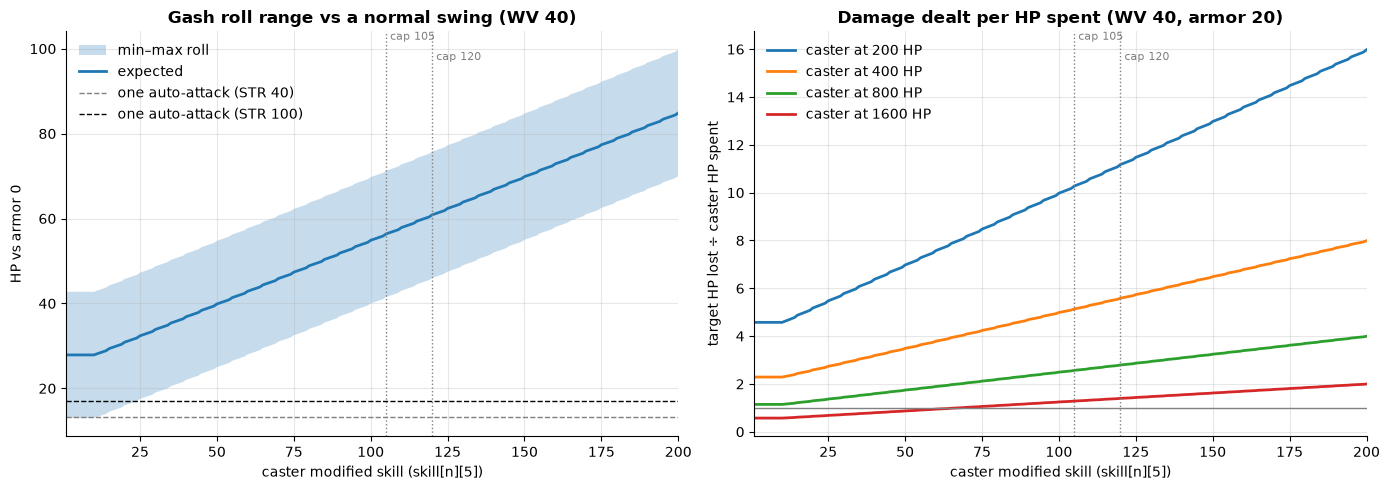

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Range of the roll: min/max/mean raw damage at WV 40.
ax = axes[0]
wv = 40
lo = gash_fixed(P, wv)
ax.fill_between(P, mm.hurt_hp(lo, 0), mm.hurt_hp(lo + 3 * wv - 1, 0), alpha=0.25, label="min–max roll")
ax.plot(P, gash_expected_hp(P, wv), label="expected")
for strength in (40, 100):
    ax.axhline(melee_expected_hp(wv, strength), ls="--", lw=1,
               label=f"one auto-attack (STR {strength})", color="tab:gray" if strength == 40 else "black")
mm.skill_axis(ax, "HP vs armor 0", "Gash roll range vs a normal swing (WV 40)")
mm.mark_caps(ax)
ax.legend()

# Value per HP spent: damage dealt / self-cost, against caster current HP.
ax = axes[1]
for hp in (200, 400, 800, 1600):
    ax.plot(P, gash_expected_hp(P, 40, armor=20) / gash_self_cost_hp(hp), label=f"caster at {hp} HP")
mm.skill_axis(ax, "target HP lost ÷ caster HP spent", "Damage dealt per HP spent (WV 40, armor 20)")
ax.axhline(1, color="grey", lw=1)
mm.mark_caps(ax)
ax.legend()
plt.tight_layout()

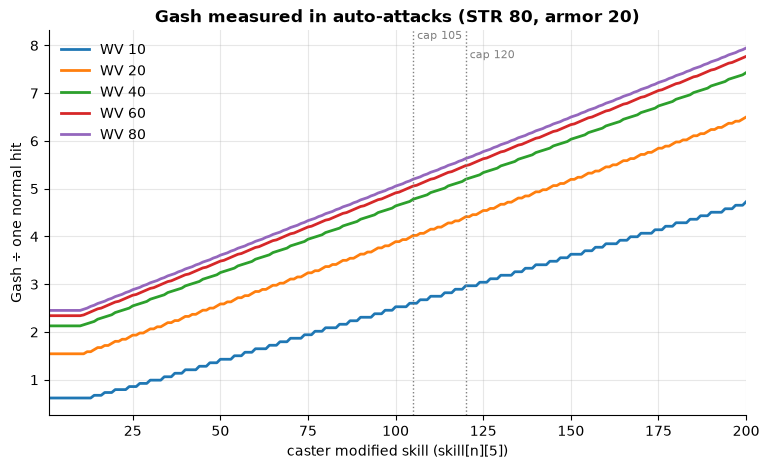

In [6]:
# Gash vs a 10 s window of auto-attacks: how many swings is one Gash worth?
fig, ax = plt.subplots()
for wv in mm.WV_SWEEP:
    swing = melee_expected_hp(wv, 80, armor=20)
    ax.plot(P, gash_expected_hp(P, wv, armor=20) / swing, label=f"WV {wv}")
mm.skill_axis(ax, "Gash ÷ one normal hit", "Gash measured in auto-attacks (STR 80, armor 20)")
mm.mark_caps(ax)
ax.legend()

# Observations

- **Linear until skill 200.** The multiplier has no soft cap. Between the raise caps (105/120)
  and 200 the fixed part still grows from about 4.2W to 7W. Gash therefore keeps paying off for
  skill gear and buffs well beyond the natural raise cap.
- **Armor is a flat tax.** Gash is type 0, so armor is subtracted once from the full hit. The
  hit is several times WV, so a given armor value removes a shrinking share of it. With WV 40,
  STR 80 and armor 20, one Gash equals about 4.8 normal hits at skill 105, 5.2 at skill 120 and
  7.4 at skill 200.
- **Self-cost is proportional to current HP.** The ratio of damage dealt to HP spent is best
  when the caster is wounded. At 200 HP the caster pays 5 HP; at 1600 HP the caster pays 40 HP
  for the same blow. The "too wounded" refusal (`a_hp ≤ cost`) only triggers at 1 milli-HP, so
  Gash remains usable at very low HP.
- **Stale comment.** `skill_gash` describes the cost as "5% of current HP, halved by the talent
  buff", but the code always charges a flat `a_hp/40` (2.5%).
- **Redundant guard.** `weapon` is already `.max(1)`, so the later `weapon.max(1) * 3` is a no-op.